In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [3]:
data = pd.read_csv(
    "seeds_dataset.txt",
    sep=r"\s+",
    header=None
)
data.columns = [
    "Area",
    "Perimeter",
    "Compactness",
    "Kernel Length",
    "Kernel Width",
    "Asymmetry Coefficient",
    "Kernel Groove Length",
    "Class"
]
X = data[["Area", "Perimeter"]]
print("Dataset shape:", X.shape)
print("\nFirst 5 rows:")
print(X.head())

Dataset shape: (210, 2)

First 5 rows:
    Area  Perimeter
0  15.26      14.84
1  14.88      14.57
2  14.29      14.09
3  13.84      13.94
4  16.14      14.99


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

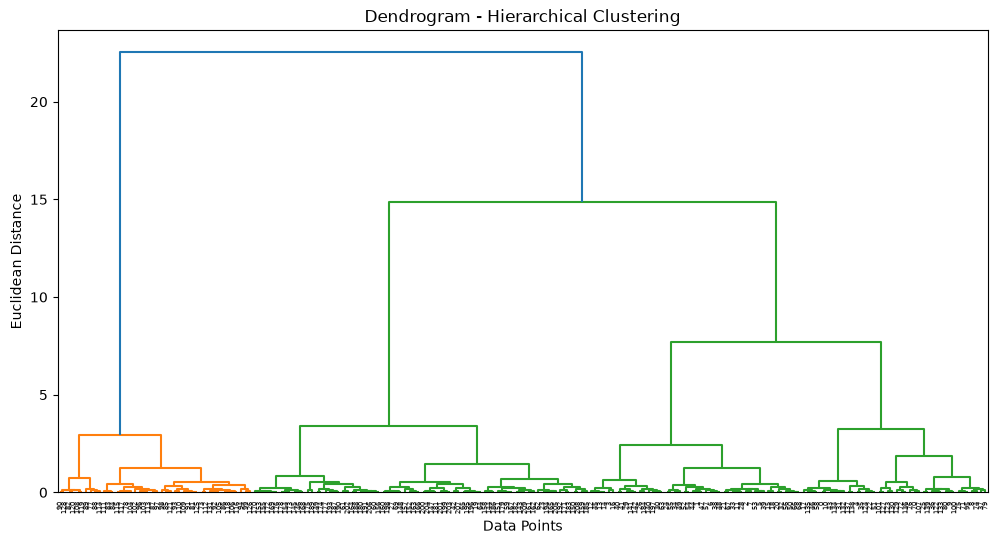

In [5]:
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linked)
plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

In [6]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)
clusters = model.fit_predict(X_scaled)

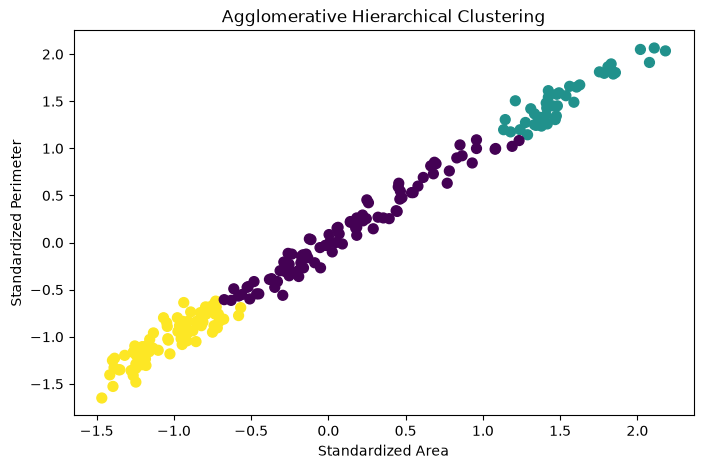

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)
plt.xlabel("Standardized Area")
plt.ylabel("Standardized Perimeter")
plt.title("Agglomerative Hierarchical Clustering")
plt.show()

In [8]:
print("\nCluster assignments:")
print(clusters)
print("\nFirst 10 data points and their clusters:")
for i in range(10):
    print("Data Point:", i, "Cluster:", clusters[i])


Cluster assignments:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 2 0 0 0 2 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 0 2 2 0 0 0 2 0 0 0 1
 0 0 0 1 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0
 2 2 2 2 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2]

First 10 data points and their clusters:
Data Point: 0 Cluster: 0
Data Point: 1 Cluster: 0
Data Point: 2 Cluster: 0
Data Point: 3 Cluster: 0
Data Point: 4 Cluster: 0
Data Point: 5 Cluster: 0
Data Point: 6 Cluster: 0
Data Point: 7 Cluster: 0
Data Point: 8 Cluster: 0
Data Point: 9 Cluster: 0
